In [382]:
# improting the basic libraries
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings 
import os
%matplotlib inline
warnings.filterwarnings('ignore')

# statistical analysis of variance 
from statsmodels.formula.api import ols


# missing value remover libraries
from lightgbm import LGBMClassifier, LGBMRegressor # also using this for model building
from sklearn.mixture import GaussianMixture
from sklearn.preprocessing import LabelEncoder



# Feature Engineering libraries
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.feature_selection import RFE, SelectKBest, chi2, f_classif, mutual_info_classif
from sklearn.model_selection import train_test_split, GridSearchCV, RandomizedSearchCV, StratifiedKFold, KFold
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import xgboost as xgb
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsRegressor


# Tensorflow libraries
import tensorflow as tf
from tensorflow import keras
from tensorflow.python.keras import layers
from tensorflow.python.keras.models import Sequential
from tensorflow.python.keras.layers import Dense, Dropout


In [383]:
train = pd.read_csv(r'D:\House Price prediction\train.csv')
train.describe(include='all')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,...,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
count,1460.000000,1460.000000,1460,1201.000000,1460.000000,1460,91,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460,1460,1460,588,1452.000000,1460,1460,1460,1423,1423,1422,1423,1460.000000,1422,1460.000000,1460.000000,1460.000000,1460,...,1460,1459,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460,1460.000000,1460,1460.000000,770,1379,1379.000000,1379,1460.000000,1460.000000,1379,1379,1460,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,7,281,54,1460.000000,1460.000000,1460.000000,1460,1460,1460.000000
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,2,5,3,25,9,8,5,8,NaN,NaN,NaN,NaN,6,8,15,16,3,NaN,4,5,6,4,4,4,6,NaN,6,NaN,NaN,NaN,6,...,2,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,7,NaN,5,6,NaN,3,NaN,NaN,5,5,3,NaN,NaN,NaN,NaN,NaN,NaN,3,4,4,NaN,NaN,NaN,9,6,NaN
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,NaN,NaN,NaN,NaN,Gable,CompShg,VinylSd,VinylSd,BrkFace,NaN,TA,TA,PConc,TA,TA,No,Unf,NaN,Unf,NaN,NaN,NaN,GasA,...,Y,SBrkr,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TA,NaN,Typ,NaN,Gd,Attchd,NaN,Unf,NaN,NaN,TA,TA,Y,NaN,NaN,NaN,NaN,NaN,NaN,Gd,MnPrv,Shed,NaN,NaN,NaN,WD,Normal,NaN
freq,NaN,NaN,1151,NaN,NaN,1454,50,925,1311,1459,1052,1382,225,1260,1445,1220,726,NaN,NaN,NaN,NaN,1141,1434,515,504,445,NaN,906,1282,647,649,1311,953,430,NaN,1256,NaN,NaN,NaN,1428,...,1365,1334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,735,NaN,1360,NaN,380,870,NaN,605,NaN,NaN,1311,1326,1340,NaN,NaN,NaN,NaN,NaN,NaN,3,157,49,NaN,NaN,NaN,1267,1198,NaN
mean,730.500000,56.897260,NaN,70.049958,10516.828082,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.099315,5.575342,1971.267808,1984.865753,NaN,NaN,NaN,NaN,NaN,103.685262,NaN,NaN,NaN,NaN,NaN,NaN,NaN,443.639726,NaN,46.549315,567.240411,1057.429452,NaN,...,NaN,NaN,1162.626712,346.992466,5.844521,1515.463699,0.425342,0.057534,1.565068,0.382877,2.866438,1.046575,NaN,6.517808,NaN,0.613014,NaN,NaN,1978.506164,NaN,1.767123,472.980137,NaN,NaN,NaN,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,NaN,NaN,NaN,43.489041,6.321918,2007.815753,NaN,NaN,180921.195890
std,421.610009,42.300571,NaN,24.284752,9981.264932,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.382997,1.112799,30.202904,20.645407,NaN,NaN,NaN,NaN,NaN,181.066207,NaN,NaN,NaN,NaN,NaN,NaN,NaN,456.098091,NaN,161.319273,441.866955,438.705324,NaN,...,NaN,NaN,386.587738,436.528436,48.623081,525.480383,0.518911,0.238753,0.550916,0.502885,0.815778,0.220338,NaN,1.625393,NaN,0.644666,NaN,NaN,24.689725,NaN,0.747315,213.804841,NaN,NaN,NaN,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,NaN,NaN,NaN,496.123024,2.703626,1.328095,NaN,NaN,79442.502883
min,1.000000,20.000000,NaN,21.000000,1300.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,1872.000000,1950.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,0.000000,NaN,...,NaN,NaN,334.000000,0.000000,0.000000,334.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,2.000000,NaN,0.000000,NaN,NaN,1900.000000,NaN,0

Trying to find out numerical columns that actually matter in canse of predicting the prices

Correlation between OverallQual and SalePrice is 0.7909816005838052
Correlation between YearBuilt and SalePrice is 0.5228973328794968
Correlation between YearRemodAdd and SalePrice is 0.5071009671113862
Correlation between TotalBsmtSF and SalePrice is 0.6135805515591954
Correlation between 1stFlrSF and SalePrice is 0.6058521846919145
Correlation between GrLivArea and SalePrice is 0.7086244776126521
Correlation between FullBath and SalePrice is 0.5606637627484456
Correlation between TotRmsAbvGrd and SalePrice is 0.5337231555820281
Correlation between GarageCars and SalePrice is 0.6404091972583522
Correlation between GarageArea and SalePrice is 0.6234314389183616


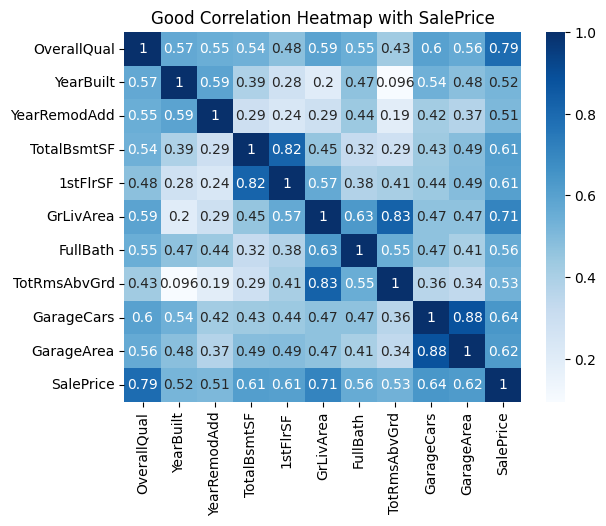

In [384]:
good_corr = []
for i in train.select_dtypes(include=['int', 'float']).columns:
    corr = np.corrcoef(train[i], train['SalePrice'])[0][1]
    if corr > 0.5 and i != 'SalePrice' or corr < -0.5:
        good_corr.append(i)
        print(f'Correlation between {i} and SalePrice is {corr}')
good_corr.append('SalePrice')
train_good_corr = train[good_corr]

sns.heatmap(train_good_corr.corr(), annot=True, cmap='Blues')
plt.title('Good Correlation Heatmap with SalePrice')
plt.show()

In [385]:
class Missing_value_analysis:
    def __init__(self, df, size):
        self.df = df.copy()
        self.size = size
        
    def analysis(self):
        for i in self.df.columns:
            if self.df[i].isna().sum() > 0: 
                print(i + ' has missing values: ' + str(self.df[i].isna().sum()))
            else: 
                pass
        for i in self.df.columns:
            if self.df[i].isna().sum() < self.df.shape[0] * self.size:
                self.df.drop(columns=[i], inplace=True)
            else: pass
        
    def missing_cols(self, cols_to_impute = []):
        for i in self.df.columns:
            if self.df[i].isna().sum() >= self.df.shape[0] * self.size:
                cols_to_impute.append(i)
        
        return(list(cols_to_impute))
        
print(Missing_value_analysis(train, 0.01).analysis())
missing_cols = Missing_value_analysis(train, 0.01).missing_cols()
print(missing_cols)

LotFrontage has missing values: 259
Alley has missing values: 1369
MasVnrType has missing values: 872
MasVnrArea has missing values: 8
BsmtQual has missing values: 37
BsmtCond has missing values: 37
BsmtExposure has missing values: 38
BsmtFinType1 has missing values: 37
BsmtFinType2 has missing values: 38
Electrical has missing values: 1
FireplaceQu has missing values: 690
GarageType has missing values: 81
GarageYrBlt has missing values: 81
GarageFinish has missing values: 81
GarageQual has missing values: 81
GarageCond has missing values: 81
PoolQC has missing values: 1453
Fence has missing values: 1179
MiscFeature has missing values: 1406
None
['LotFrontage', 'Alley', 'MasVnrType', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'FireplaceQu', 'GarageType', 'GarageYrBlt', 'GarageFinish', 'GarageQual', 'GarageCond', 'PoolQC', 'Fence', 'MiscFeature']


## Handling the Missing numeric values

In [386]:
class Handling_Numerical_Missing_values:
    def __init__(self, df):
        self.df = df
        self.missing_cols = None  
        self.numeric_missing_cols = None

    def extracting_missing_cols(self):
        # Assuming Missing_value_analysis is defined elsewhere
        self.missing_cols = list(set(Missing_value_analysis(self.df, 0.01).missing_cols()))
        return self.missing_cols

    def copying(self):
        if self.missing_cols is None:
            self.extracting_missing_cols()
        data = self.df[self.missing_cols].copy()
        return data
    
    def getting_numeric_cols(self):
        if self.numeric_missing_cols is None:
            data = self.copying()
            self.numeric_missing_cols = data.select_dtypes(include=['int', 'float']).columns.tolist()
        return self.numeric_missing_cols
    
    def getting_categorical_cols(self):
        data = self.copying()
        categorical_missing_cols = data.select_dtypes(include=['object', 'category']).columns.tolist()
        return categorical_missing_cols
    
    def main(self):
        data = self.copying()
        
        
        for i in self.numeric_missing_cols:
            
            def splitting_feature(data):
                nan_col_name = f'nan_{i}'
                data[nan_col_name] = 0
                data.loc[data[i].isna(), nan_col_name] = 1
                
                trainnum = data[data[nan_col_name] == 0]
                testnum = data[data[nan_col_name] == 1]
                return nan_col_name, trainnum, testnum        
            nan_col_name, trainnum, testnum = splitting_feature(data)
            
            def preparing_feature(nan_col_name, trainnum, testnum):
                xtrain = pd.get_dummies(trainnum.drop(columns=[i, nan_col_name]))
                xtest = pd.get_dummies(testnum.drop(columns=[i, nan_col_name]))
                ytrain = trainnum[i]
                xtest = xtest.reindex(columns=xtrain.columns, fill_value=0) # this is very important, otherwise the indexes of test data will not match of the train data
                return xtrain, xtest, ytrain
            xtrain, xtest, ytrain = preparing_feature(nan_col_name, trainnum, testnum)
            
            def lgbm(xtrain, ytrain, xtest):
                lgbmr = LGBMRegressor(random_state=42, verbose = 1, n_jobs = 1)
                lgbmr.fit(xtrain, ytrain)
                ypred = lgbmr.predict(xtest)
                return ypred
            
            predicted_values = lgbm(xtrain, ytrain, xtest)
            self.df.loc[self.df[i].isna(), i] = predicted_values
# Usage
handler = Handling_Numerical_Missing_values(train)
missing_cols = handler.extracting_missing_cols()  
numeric_missing_cols = handler.getting_numeric_cols()
categorical_missing_cols = handler.getting_categorical_cols()


### Exectuting the final code for numerical missing value imputation
handler.main()
train[numeric_missing_cols].isna().sum()   

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000672 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 173
[LightGBM] [Info] Number of data points in the train set: 1379, number of used features: 44
[LightGBM] [Info] Start training from score 1978.506164
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000168 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 175
[LightGBM] [Info] Number of data points in the train set: 1201, number of used features: 45
[LightGBM] [Info] Start training from score 70.049958


GarageYrBlt    0
LotFrontage    0
dtype: int64

In [387]:
train[categorical_missing_cols].isna().sum()    

Fence           1179
BsmtCond          37
BsmtFinType2      38
BsmtExposure      38
FireplaceQu      690
GarageType        81
PoolQC          1453
BsmtQual          37
GarageQual        81
GarageCond        81
MiscFeature     1406
GarageFinish      81
BsmtFinType1      37
Alley           1369
MasVnrType       872
dtype: int64

In [388]:
sale = train['SalePrice']
numeric = train.select_dtypes(include=['int', 'float'])

for i in numeric:
    q1 = train[i].quantile(0.25)
    q3 = train[i].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    outliers = train[(train[i] < lower_bound) | (train[i] > upper_bound)][i]
    if outliers.empty == 0:
        print(f'{i} has {len(outliers)} outliers')


MSSubClass has 103 outliers
LotFrontage has 93 outliers
LotArea has 69 outliers
OverallQual has 2 outliers
OverallCond has 125 outliers
YearBuilt has 7 outliers
MasVnrArea has 96 outliers
BsmtFinSF1 has 7 outliers
BsmtFinSF2 has 167 outliers
BsmtUnfSF has 29 outliers
TotalBsmtSF has 61 outliers
1stFlrSF has 20 outliers
2ndFlrSF has 2 outliers
LowQualFinSF has 26 outliers
GrLivArea has 31 outliers
BsmtFullBath has 1 outliers
BsmtHalfBath has 82 outliers
BedroomAbvGr has 35 outliers
KitchenAbvGr has 68 outliers
TotRmsAbvGrd has 30 outliers
Fireplaces has 5 outliers
GarageYrBlt has 1 outliers
GarageCars has 5 outliers
GarageArea has 21 outliers
WoodDeckSF has 32 outliers
OpenPorchSF has 77 outliers
EnclosedPorch has 208 outliers
3SsnPorch has 24 outliers
ScreenPorch has 116 outliers
PoolArea has 7 outliers
MiscVal has 52 outliers
SalePrice has 61 outliers


In [389]:
train2 = train.copy()

In [390]:
le = LabelEncoder()
all_categories =  train2.select_dtypes(include=['object', 'category']).columns.tolist()

df_train = train2[train2.notna()].copy
df_missing = train2[train2.isna().any(axis=1)].copy
print(all_categories)

for i in all_categories:
    print(len(train2[i].unique()))

['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2', 'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual', 'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual', 'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature', 'SaleType', 'SaleCondition']
5
2
3
4
4
2
5
3
25
9
8
5
8
6
8
15
16
4
4
5
6
5
5
5
7
7
6
5
2
6
4
7
6
7
4
6
6
3
4
5
5
9
6


In [391]:
X = (train.drop(columns=['SalePrice'], axis = 1))
y = train['SalePrice']
y_binned = np.floor(np.log1p(y))
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.1, random_state=42, stratify = None)

In [392]:
X_train.shape

(1314, 80)

In [393]:
test = pd.read_csv(r'D:\House Price prediction\test.csv')
test.describe(include='all')

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition
count,1459.000000,1459.000000,1455,1232.000000,1459.000000,1459,107,1459,1459,1457,1459,1459,1459,1459,1459,1459,1459,1459.000000,1459.000000,1459.000000,1459.000000,1459,1459,1458,1458,565,1444.000000,1459,1459,1459,1415,1414,1415,1417,1458.000000,1417,1458.000000,1458.000000,1458.000000,1459,1459,1459,1459,1459.000000,1459.000000,1459.000000,1459.000000,1457.000000,1457.000000,1459.000000,1459.000000,1459.000000,1459.000000,1458,1459.000000,1457,1459.00000,729,1383,1381.000000,1381,1458.000000,1458.000000,1381,1381,1459,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,1459.000000,3,290,51,1459.000000,1459.000000,1459.000000,1458,1459
unique,NaN,NaN,5,NaN,NaN,2,2,4,4,1,5,3,25,9,5,5,7,NaN,NaN,NaN,NaN,6,4,13,15,3,NaN,4,5,6,4,4,4,6,NaN,6,NaN,NaN,NaN,4,5,2,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4,NaN,7,NaN,5,6,NaN,3,NaN,NaN,4,5,3,NaN,NaN,NaN,NaN,NaN,NaN,2,4,3,NaN,NaN,NaN,9,6
top,NaN,NaN,RL,NaN,NaN,Pave,Grvl,Reg,Lvl,AllPub,Inside,Gtl,NAmes,Norm,Norm,1Fam,1Story,NaN,NaN,NaN,NaN,Gable,CompShg,VinylSd,VinylSd,BrkFace,NaN,TA,TA,PConc,TA,TA,No,GLQ,NaN,Unf,NaN,NaN,NaN,GasA,Ex,Y,SBrkr,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,TA,NaN,Typ,NaN,Gd,Attchd,NaN,Unf,NaN,NaN,TA,TA,Y,NaN,NaN,NaN,NaN,NaN,NaN,Ex,MnPrv,Shed,NaN,NaN,NaN,WD,Normal
freq,NaN,NaN,1114,NaN,NaN,1453,70,934,1311,1457,1081,1396,218,1251,1444,1205,745,NaN,NaN,NaN,NaN,1169,1442,510,510,434,NaN,892,1256,661,634,1295,951,431,NaN,1237,NaN,NaN,NaN,1446,752,1358,1337,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,757,NaN,1357,NaN,364,853,NaN,625,NaN,NaN,1293,1328,1301,NaN,NaN,NaN,NaN,NaN,NaN,2,172,46,NaN,NaN,NaN,1258,1204
mean,2190.000000,57.378341,NaN,68.580357,9819.161069,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,6.078821,5.553804,1971.357779,1983.662783,NaN,NaN,NaN,NaN,NaN,100.709141,NaN,NaN,NaN,NaN,NaN,NaN,NaN,439.203704,NaN,52.619342,554.294925,1046.117970,NaN,NaN,NaN,NaN,1156.534613,325.967786,3.543523,1486.045922,0.434454,0.065202,1.570939,0.377656,2.854010,1.042495,NaN,6.385195,NaN,0.58122,NaN,NaN,1977.721217,NaN,1.766118,472.768861,NaN,NaN,NaN,93.174777,48.313914,24.243317,1.794380,17.064428,1.744345,NaN,NaN,NaN,58.167923,6.104181,2007.769705,NaN,NaN
std,421.321334,42.746880,NaN,22.376841,4955.517327,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.436812,1.113740,30.390071,21.130467,NaN,NaN,NaN,NaN,NaN,177.625900,NaN,NaN,NaN,NaN,NaN,NaN,NaN,455.268042,NaN,176.753926,437.260486,442.898624,NaN,NaN,NaN,NaN,398.165820,420.610226,44.043251,485.566099,0.530648,0.252468,0.555190,0.503017,0.829788,0.208472,NaN,1.508895,NaN,0.64742,NaN,NaN,26.431175,NaN,0.775945,217.048611,NaN,NaN,NaN,127.744882,68.883364,67.227765,20.207842,56.609763,30.491646,NaN,NaN,NaN,630.806978,2.722432,1.301740,NaN,NaN
min,1461.000000,20.000000,NaN,21.000000,1470.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.000000,1.000000,1879.000000,1950.000000,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000000,NaN,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN,407.000000,0.000000,0.000000,407.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,3.000000,NaN,0.00000,NaN,NaN,1895.000000,NaN,0.000000,0.000000,NaN,NaN,NaN,0.000000,0.000000,0.000000,0

In [394]:
num = train.select_dtypes(include=['int', 'float']).drop(columns=['SalePrice'])
cat = train.select_dtypes(include=['object', 'category'])

In [395]:
categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

numerical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numerical_transformer, num.columns),
        ('cat', categorical_transformer, cat.columns)
    ])  


In [396]:
X_train_preprocessed = preprocessor.fit_transform(X_train)
X_test_preprocessed = preprocessor.transform(X_test)
y_train_preprocessed = y_train
y_test_preprocessed = y_test



### Trying out models and judding them based on their MAE and scores

In [397]:
neighbors = np.arange(1, 11)
train_accuracies = {}
test_accuracies = {}
for k in neighbors:
    knn = KNeighborsRegressor(n_neighbors=k)
    knn.fit(X_train_preprocessed, y_train_preprocessed)
    train_accuracies[k] = knn.score(X_train_preprocessed, y_train_preprocessed)
    test_accuracies[k] = knn.score(X_test_preprocessed, y_test_preprocessed)

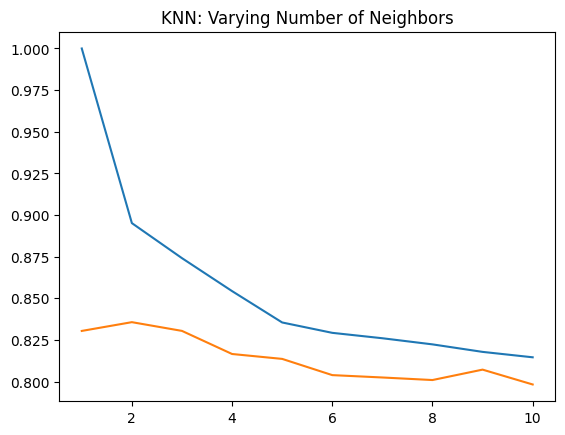

In [398]:
plt.title('KNN: Varying Number of Neighbors')

plt.plot(neighbors, list(train_accuracies.values()), label='Train Accuracy')
plt.plot(neighbors, list(test_accuracies.values()), label = 'Test Accuracy')

From the graph we can tell that the model perfors well when the nuumber of neighbors is 7.7.

In [399]:
new_model = KNeighborsRegressor(n_neighbors=9)
new_model.fit(X_train_preprocessed, y_train_preprocessed)   

KNeighborsRegressor(n_neighbors=9)

In [400]:
pred = new_model.predict(X_test_preprocessed)
mae = mean_absolute_error(y_test_preprocessed, pred)    
print(mae)
print('Model Accuracy:', new_model.score(X_test_preprocessed, y_test_preprocessed))

21987.661339421615
Model Accuracy: 0.8071699565413868


In [401]:
depths = np.arange(1, 10)
depth_train_accuracies = {}
depth_test_accuracies = {} 
for k in depths:
    xgb_model = xgb.XGBRegressor(objective ='reg:squarederror', colsample_bytree = 0.3, learning_rate = 0.1, max_depth = k, alpha = 10, n_estimators = 10)
    xgb_model.fit(X_train_preprocessed, y_train_preprocessed)
    depth_train_accuracies[k] = xgb_model.score(X_train_preprocessed, y_train_preprocessed)
    depth_test_accuracies[k] = xgb_model.score(X_test_preprocessed, y_test_preprocessed)

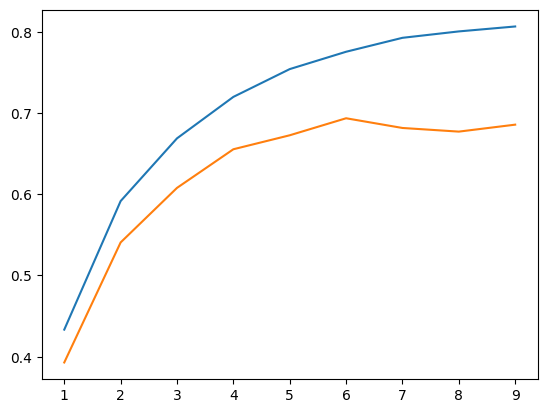

In [402]:
plt.plot(depths, list(depth_train_accuracies.values()), label='Train Accuracy')
plt.plot(depths, list(depth_test_accuracies.values()), label='Test Accuracy')

depths = 2 is the best depth for the model.

In [403]:
new_xgb = xgb.XGBRegressor(objective ='reg:squarederror', colsample_bytree = 0.3, learning_rate = 0.1, max_depth = 2, alpha = 10, n_estimators = 10)
new_xgb.fit(X_train_preprocessed, y_train_preprocessed)
new_xgb_pred = new_xgb.predict(X_test_preprocessed) 

mae_xgb = mean_absolute_error(y_test_preprocessed, new_xgb_pred)
print(mae_xgb)
new_xgb.score(X_test_preprocessed, y_test_preprocessed)

39611.0859375


0.5406942367553711

XGB does not perform well on this dataset.

In [404]:
X_train_preprocessed.shape

(1314, 287)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001022 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3731
[LightGBM] [Info] Number of data points in the train set: 1314, number of used features: 184
[LightGBM] [Info] Start training from score 180704.734399
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.000806 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3731
[LightGBM] [Info] Number of data points in the train set: 1314, number of used features: 184
[LightGBM] [Info] Start training from score 180704.734399
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf
[LightGBM] [Info] Auto-choos

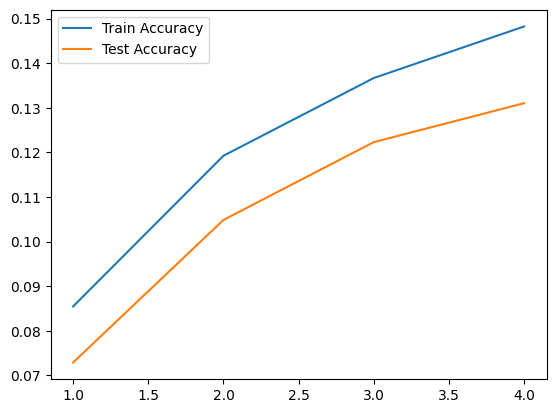

In [405]:
lgbm_range = np.arange(1, 5) 
lgbm_train_accuracies = {}
lgbm_test_accuracies = {}

for i in lgbm_range:
    lgbm_model = LGBMRegressor(verbose = 1, n_jobs = 1, n_estimators = 1, max_depth = i)
    lgbm_model.fit(X_train_preprocessed, y_train_preprocessed)
    lgbm_pred = lgbm_model.predict(X_test_preprocessed)
    lgbm_train_accuracies[i] = lgbm_model.score(X_train_preprocessed, y_train_preprocessed)
    lgbm_test_accuracies[i] = lgbm_model.score(X_test_preprocessed, y_test_preprocessed)
    
plt.plot(lgbm_range, list(lgbm_train_accuracies.values()), label='Train Accuracy')
plt.plot(lgbm_range, list(lgbm_test_accuracies.values()), label='Test Accuracy')
plt.legend()
plt.show()

In [406]:
new_lgbm_model = LGBMRegressor(verbose = 1, n_jobs = 1, n_estimators = 1, max_depth = 3)
new_lgbm_model.fit(X_train_preprocessed, y_train_preprocessed)
new_lgbm_model.score(X_test_preprocessed, y_test_preprocessed)

[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001091 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 3731
[LightGBM] [Info] Number of data points in the train set: 1314, number of used features: 184
[LightGBM] [Info] Start training from score 180704.734399
[LightGBM] [Warning] No further splits with positive gain, best gain: -inf


0.12230208142694154

LGBM performed horribly on this dataset.

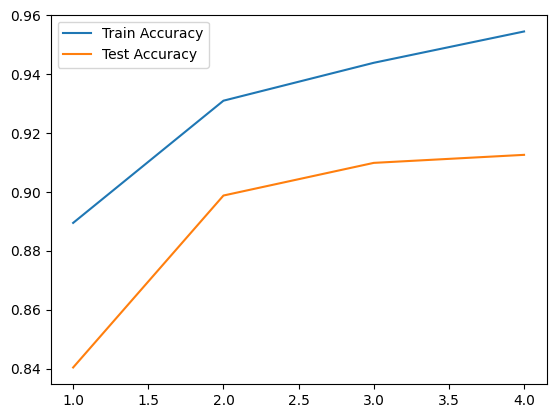

In [407]:
rf_range = np.arange(1, 5) 
rf_train_accuracies = {}
rf_test_accuracies = {}
for i in rf_range:
    random_forest = RandomForestRegressor(n_estimators=i, random_state=2)
    random_forest.fit(X_train_preprocessed, y_train_preprocessed)
    rf_test_accuracies[i] = random_forest.score(X_test_preprocessed, y_test_preprocessed)
    rf_train_accuracies[i] = random_forest.score(X_train_preprocessed, y_train_preprocessed)
plt.plot(rf_range, list(rf_train_accuracies.values()), label='Train Accuracy')
plt.plot(rf_range, list(rf_test_accuracies.values()), label='Test Accuracy')
plt.legend()
plt.show()

In [408]:
new_rf_model  = RandomForestRegressor(n_estimators=2, random_state=2)
new_rf_model.fit(X_train_preprocessed, y_train_preprocessed)
new_rf_model.score(X_test_preprocessed, y_test_preprocessed)
mean_absolute_error(y_test_preprocessed, new_rf_model.predict(X_test_preprocessed))
print('Model Accuracy:', new_rf_model.score(X_test_preprocessed, y_test_preprocessed),'\n', "Mean Absolute Error:", mean_absolute_error(y_test_preprocessed, new_rf_model.predict(X_test_preprocessed))    )

Model Accuracy: 0.8987944824362416 
 Mean Absolute Error: 20324.445205479453


Random forest performed decently on this dataset.

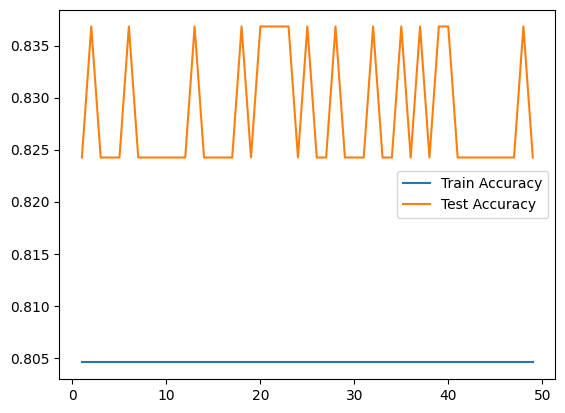

In [409]:
dt_range = np.arange(1, 50)
dt_train_score = {}
dt_test_score = {}
for i in dt_range:
    dt_regressor = DecisionTreeRegressor(max_depth=4, random_state= i)
    dt_regressor.fit(X_train_preprocessed, y_train_preprocessed)
    dt_train_score[i] = dt_regressor.score(X_train_preprocessed, y_train_preprocessed)
    dt_test_score[i] = dt_regressor.score(X_test_preprocessed, y_test_preprocessed)
plt.plot(dt_range, list(dt_train_score.values()), label='Train Accuracy')
plt.plot(dt_range, list(dt_test_score.values()), label='Test Accuracy')
plt.legend()
plt.show()

Max depth is 4


In [410]:
new_dt_model = DecisionTreeRegressor(max_depth=4, random_state= 30)
new_dt_model.fit(X_train_preprocessed, y_train_preprocessed)
new_dt_model.score(X_test_preprocessed, y_test_preprocessed)

0.8242447407373132

Decision tree performs slightly better than the random forest.

In [411]:
nb_model = GaussianNB()
nb_model.fit(X_train_preprocessed.toarray(), y_train_preprocessed)
nb_model.score(X_test_preprocessed.toarray(), y_test_preprocessed)

0.0136986301369863

In [412]:

class model_convergence_test:
    def __init__(self, model, X_train, y_train, X_test, y_test, rs_end=42, depth_end=20):
        self.model = model
        self.X_train = X_train
        self.y_train = y_train
        self.X_test = X_test
        self.y_test = y_test
        self.rs_end = rs_end
        self.depth_end = depth_end

    def fit_model(self):
        self.model.fit(self.X_train, self.y_train)
        return self.model

    def evaluate_model(self):
        train_score = self.model.score(self.X_train, self.y_train)
        test_score = self.model.score(self.X_test, self.y_test)
        return train_score, test_score

    def check_convergence(self):
        train_score, test_score = self.evaluate_model()
        return abs(train_score - test_score) < 0.05

    def random_state_tuning(self):
        random_range = np.arange(1, self.rs_end)
        train_accuracies = {}
        test_accuracies = {}

        for rs in random_range:
            self.model.random_state = rs
            self.fit_model()
            train_score, test_score = self.evaluate_model()
            train_accuracies[rs] = train_score
            test_accuracies[rs] = test_score

        plt.plot(random_range, list(train_accuracies.values()), label='Train Accuracy')
        plt.plot(random_range, list(test_accuracies.values()), label='Test Accuracy')
        plt.xlabel("Random State")
        plt.ylabel("Score")
        plt.title("Random State Tuning")
        plt.legend()
        plt.show()
        
    def depth_tuning(self):
        depth_range = np.arange(1, self.depth_end)
        train_accuracies = {}
        test_accuracies = {}

        for depth in depth_range:
            self.model.max_depth = depth
            self.fit_model()
            train_score, test_score = self.evaluate_model()
            train_accuracies[depth] = train_score
            test_accuracies[depth] = test_score

        plt.plot(depth_range, list(train_accuracies.values()), label='Train Accuracy')
        plt.plot(depth_range, list(test_accuracies.values()), label='Test Accuracy')
        plt.xlabel("Max Depth")
        plt.ylabel("Score")
        plt.title("Max Depth Tuning")
        plt.legend()
        plt.show()

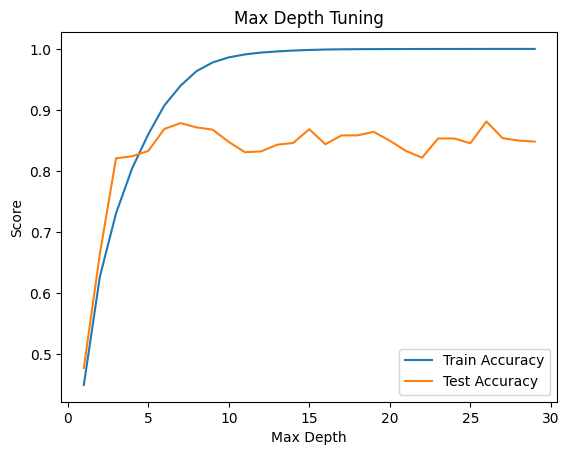

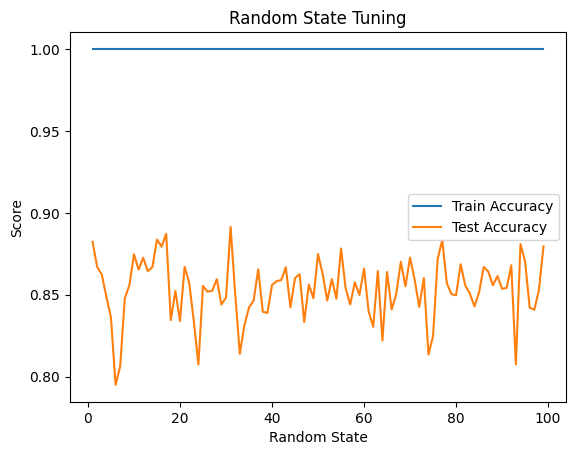

In [413]:
tested_dt = model_convergence_test(
    model = DecisionTreeRegressor(max_depth=4, random_state= 30),
    X_train = X_train_preprocessed,
    y_train = y_train_preprocessed,
    X_test = X_test_preprocessed,
    y_test = y_test_preprocessed,
    rs_end=100,
    depth_end=30
)

tested_dt.depth_tuning()
tested_dt.random_state_tuning()